Loading Training Data...

--- Training Random Forest Models (1841 total rounds) ---
Epoch   0 | Features: 200 | Train F1 (Macro): 0.5620
Epoch  10 | Features: 200 | Train F1 (Macro): 1.0000
Epoch  20 | Features: 200 | Train F1 (Macro): 1.0000
Epoch  30 | Features: 200 | Train F1 (Macro): 1.0000
Epoch  40 | Features: 200 | Train F1 (Macro): 1.0000
Epoch  50 | Features: 200 | Train F1 (Macro): 1.0000
Epoch  60 | Features: 200 | Train F1 (Macro): 1.0000
Epoch End | Features: 200 | Train F1 (Macro): 1.0000

--- Evaluating Models & Generating Predictions for 23 Test Matches ---

--- Testing Results Summary ---
Epoch   0 | Test F1 (Macro): 0.4913
Epoch  10 | Test F1 (Macro): 0.5611
Epoch  20 | Test F1 (Macro): 0.6065
Epoch  30 | Test F1 (Macro): 0.6417
Epoch  40 | Test F1 (Macro): 0.6744
Epoch  50 | Test F1 (Macro): 0.7093
Epoch  60 | Test F1 (Macro): 0.7203
Epoch End | Test F1 (Macro): 0.7662

Saved prediction files to: D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\Results\

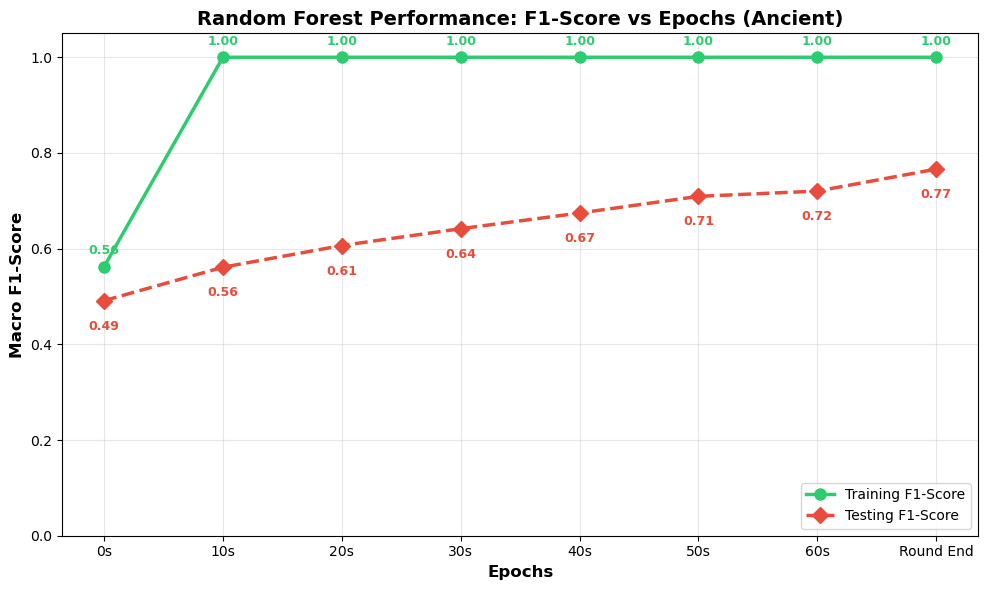

In [1]:
import os
import glob
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# ==========================================
# 1. CONFIGURATION & PATHS
# ==========================================
# Change the Drive letter to "F" or "D" depending on the mounted drive in the PC
TRAIN_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\FeatData\Wfire_STOMS_01\Training\Ancient")
TEST_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\FeatData\Wfire_STOMS_01\Testing\Ancient")
RESULTS_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\Results\STOMs\RF_MAPWISE_01\Ancient")

EPOCHS = ["0", "10", "20", "30", "40", "50", "60", "End"]

# ==========================================
# 2. DATA RETRIEVAL (Helper)
# ==========================================
def load_and_combine_data(data_dir):
    """Reads all match CSVs in a directory and combines them into a single DataFrame."""
    if not data_dir.exists():
        print(f"Error: Directory not found -> {data_dir}")
        return None
        
    csv_files = list(data_dir.glob("*.csv"))
    if not csv_files:
        print(f"No CSV files found in -> {data_dir}")
        return None

    df_list = []
    for f in csv_files:
        try:
            df = pl.read_csv(f)
            if "target" in df.columns:
                df_list.append(df)
        except Exception as e:
            print(f"Error reading {f.name}: {e}")
            
    if not df_list:
        return None
        
    return pl.concat(df_list, how="vertical").drop_nulls(subset=["target"])

# ==========================================
# 3. MODEL TRAINING & TRAIN EVALUATION
# ==========================================
def train_and_eval_train(train_df):
    """Trains a Random Forest per epoch and computes training F1-scores."""
    models = {}
    train_f1_scores = []
    
    y_train = train_df["target"].to_numpy()
    
    print(f"\n--- Training Random Forest Models ({len(train_df)} total rounds) ---")
    for e_str in EPOCHS:
        # Isolate features specific to this epoch
        epoch_cols = [col for col in train_df.columns if f"_e{e_str}_" in col]
        
        if not epoch_cols:
            print(f"Warning: No features found for epoch {e_str}")
            train_f1_scores.append(0)
            continue
            
        X_train = train_df.select(epoch_cols).to_numpy()
        
        # Train Model
        rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
        rf.fit(X_train, y_train)
        
        # Predict on Training Data for F1 Evaluation
        y_train_pred = rf.predict(X_train)
        f1 = f1_score(y_train, y_train_pred, average="macro")
        train_f1_scores.append(f1)
        
        models[e_str] = {"model": rf, "features": epoch_cols}
        print(f"Epoch {e_str:>3} | Features: {len(epoch_cols):>3} | Train F1 (Macro): {f1:.4f}")
        
    return models, train_f1_scores

# ==========================================
# 4. TESTING, SAVING PREDICTIONS & TEST EVAL
# ==========================================
def evaluate_and_save_test_predictions(models):
    """Generates test predictions, saves CSVs, and computes test F1-scores."""
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    test_files = list(TEST_DIR.glob("*.csv"))
    
    # Tracking for global test evaluation
    test_actuals = []
    test_preds = {e: [] for e in EPOCHS}

    print(f"\n--- Evaluating Models & Generating Predictions for {len(test_files)} Test Matches ---")
    
    for filepath in test_files:
        match_id = filepath.stem
        try:
            df_test = pl.read_csv(filepath).drop_nulls(subset=["target"])
            if df_test.is_empty():
                continue
                
            y_test_match = df_test["target"].to_list()
            test_actuals.extend(y_test_match)
            
            # Setup output dictionary with 'round' as first column
            out_data = {"round": df_test["round"].to_list()}
            
            # Generate predictions per epoch
            for e_str in EPOCHS:
                if e_str not in models:
                    continue
                    
                rf_model = models[e_str]["model"]
                feature_cols = models[e_str]["features"]
                
                X_test = df_test.select(feature_cols).to_numpy()
                predictions = rf_model.predict(X_test)
                
                out_data[f"pred_epoch_{e_str}"] = predictions
                test_preds[e_str].extend(predictions)
                
            # Append target as the final column
            out_data["actual_winner"] = y_test_match
            
            # Reorder columns to ensure 'round' is first and 'actual_winner' is last
            col_order = ["round"] + [f"pred_epoch_{e}" for e in EPOCHS if e in models] + ["actual_winner"]
            
            # Save specific match file
            out_df = pl.DataFrame(out_data).select(col_order)
            out_df.write_csv(RESULTS_DIR / f"{match_id}.csv")
            
        except Exception as e:
            print(f"Error processing test file {match_id}: {e}")

    # Compute Test F1 Scores
    test_f1_scores = []
    print("\n--- Testing Results Summary ---")
    for e_str in EPOCHS:
        if test_preds[e_str]:
            f1 = f1_score(test_actuals, test_preds[e_str], average="macro")
            test_f1_scores.append(f1)
            print(f"Epoch {e_str:>3} | Test F1 (Macro): {f1:.4f}")
        else:
            test_f1_scores.append(0)

    print(f"\nSaved prediction files to: {RESULTS_DIR}")
    return test_f1_scores

# ==========================================
# 5. VISUALIZATION
# ==========================================
def plot_f1_scores(train_f1, test_f1):
    """Plots Training vs Testing F1-Scores across epochs."""
    plt.figure(figsize=(10, 6))
    
    x_labels = [f"{e}s" if e != "End" else "Round End" for e in EPOCHS]
    
    # Plotting Train and Test lines
    plt.plot(x_labels, train_f1, marker='o', markersize=8, color="#2ecc71", linewidth=2.5, label="Training F1-Score")
    plt.plot(x_labels, test_f1, marker='D', markersize=8, color="#e74c3c", linewidth=2.5, linestyle="--", label="Testing F1-Score")
    
    # Formatting
    plt.title("Random Forest Performance: F1-Score vs Epochs (Ancient)", fontsize=14, fontweight='bold')
    plt.xlabel("Epochs", fontsize=12, fontweight='bold')
    plt.ylabel("Macro F1-Score", fontsize=12, fontweight='bold')
    plt.ylim(0.0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='lower right')
    
    # Annotate points
    for i, (tr_val, te_val) in enumerate(zip(train_f1, test_f1)):
        plt.text(i, tr_val + 0.02, f"{tr_val:.2f}", ha='center', va='bottom', color="#2ecc71", fontweight='bold', fontsize=9)
        plt.text(i, te_val - 0.04, f"{te_val:.2f}", ha='center', va='top', color="#e74c3c", fontweight='bold', fontsize=9)

    plt.tight_layout()
    plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    print("Loading Training Data...")
    train_data = load_and_combine_data(TRAIN_DIR)
    
    if train_data is not None:
        # Step 2: Train models & Eval Train F1
        trained_models, train_f1s = train_and_eval_train(train_data)
        
        # Step 3 & 4: Test models, Save Results, & Eval Test F1
        if trained_models:
            test_f1s = evaluate_and_save_test_predictions(trained_models)
            
            # Step 5: Visualize
            plot_f1_scores(train_f1s, test_f1s)